# Student Performance Prediction using Artificial Neural Network (ANN)

**Objective:** Predict `final_grade` (a continuous score, i.e. this is a **regression** problem) using an ANN built with TensorFlow/Keras.

**Dataset:** `student_performance_prediction_dataset-2.csv`

This notebook covers: EDA → Preprocessing → Multiple ANN architectures (different activations, optimizers, epochs) → Model comparison → Final predictions → Conclusion.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

pd.set_option('display.max_columns', None)
print("TensorFlow version:", tf.__version__)

I0000 00:00:1787968792.825756    3266 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787968792.826376    3266 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787968792.889345    3266 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787968794.240172    3266 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787968794.240603    3266 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


## 1. Load Dataset & Basic EDA

In [2]:
df = pd.read_csv('student_performance_prediction_dataset-2.csv')
print("Shape:", df.shape)
df.head()

Shape: (300000, 25)


,student_id,age,gender,study_hours,attendance,sleep_hours,previous_grade,assignments_completed,practice_tests_taken,group_study_hours,notes_quality_score,time_management_score,motivation_level,mental_health_score,screen_time,social_media_hours,family_income,parent_education,internet_access,device_type,school_type,extracurriculars,final_grade,grade_category,pass_fail
0,1,21,Male,1.645404,79.154521,8.230886,96.053840,7.719620,1.871170,1.447894,6.811654,7.316867,9.045441,7.762145,1.549443,4.018412,Medium,Master,Yes,Mobile,Private,Coding Club,59.248749,D,Pass
1,2,18,Male,4.462126,72.526685,6.139219,53.024821,6.754758,5.630071,1.891288,10.000000,10.000000,9.810884,4.229670,5.458155,3.268642,Medium,Master,Yes,Laptop,Public,NaN,58.595595,D,Pass
2,3,19,Female,6.220212,98.531716,6.946313,78.775422,10.000000,7.862877,1.774356,6.484908,3.618888,10.000000,7.583075,0.000000,2.327293,Low,High School,Yes,Tablet,Private,Music,85.855289,A,Pass
3,4,21,Female,1.826644,97.731245,8.297048,76.122618,7.440486,2.316252,1.204271,6.057978,5.366866,5.935404,4.978907,5.325794,1.163367,Medium,Bachelor,Yes,Laptop,Public,Debate,42.117503,F,Fail
4,5,17,Male,3.789322,78.589107,6.777171,81.305681,9.962609,5.335697,1.399230,9.013332,5.613393,5.431089,5.677695,4.416843,0.411183,High,High School,Yes,Laptop,Private,Debate,62.870474,C,Pass


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 25 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   student_id             300000 non-null  int64  
 1   age                    300000 non-null  int64  
 2   gender                 300000 non-null  str    
 3   study_hours            300000 non-null  float64
 4   attendance             300000 non-null  float64
 5   sleep_hours            300000 non-null  float64
 6   previous_grade         300000 non-null  float64
 7   assignments_completed  300000 non-null  float64
 8   practice_tests_taken   300000 non-null  float64
 9   group_study_hours      300000 non-null  float64
 10  notes_quality_score    300000 non-null  float64
 11  time_management_score  300000 non-null  float64
 12  motivation_level       300000 non-null  float64
 13  mental_health_score    300000 non-null  float64
 14  screen_time            300000 non-null  float64

In [4]:
df.describe()

,student_id,age,study_hours,attendance,sleep_hours,previous_grade,assignments_completed,practice_tests_taken,group_study_hours,notes_quality_score,time_management_score,motivation_level,mental_health_score,screen_time,social_media_hours,final_grade
count,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000
mean,150000.500000,17.999070,4.503062,84.699395,6.991431,69.840184,7.836044,4.017508,1.529057,6.946017,6.464472,6.945851,6.984210,4.018094,2.530258,53.089206
std,86602.684716,1.999235,1.978513,9.419450,1.463070,14.683157,1.732474,1.956444,0.941525,1.885193,1.925801,1.886246,1.471193,1.958596,1.435742,12.225161
min,1.000000,15.000000,0.000000,40.000000,3.000000,20.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,75000.750000,16.000000,3.143566,78.241008,5.992666,59.870863,6.654817,2.655243,0.826462,5.653740,5.138654,5.655885,5.982593,2.650836,1.491633,44.867737
50%,150000.500000,18.000000,4.498272,84.990371,6.999011,69.955736,8.000829,4.001981,1.499206,7.011212,6.493222,7.005390,6.992543,3.997134,2.498493,53.167495
75%,225000.250000,20.000000,5.843646,91.732244,8.013284,80.102857,9.357154,5.349494,2.172680,8.356150,7.845919,8.356416,8.010331,5.350158,3.513496,61.379373
max,300000.000000,21.000000,12.000000,100.000000,10.000000,100.000000,10.000000,10.000000,5.840593,10.000000,10.000000,10.000000,10.000000,12.000000,8.000000,100.000000


In [5]:
# Check categorical columns and their unique values
cat_cols = ['gender', 'family_income', 'parent_education', 'internet_access',
            'device_type', 'school_type', 'extracurriculars', 'grade_category', 'pass_fail']
for c in cat_cols:
    print(f"{c}: {df[c].unique()}")

gender: <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
family_income: <StringArray>
['Medium', 'Low', 'High']
Length: 3, dtype: str
parent_education: <StringArray>
['Master', 'High School', 'Bachelor', 'PhD']
Length: 4, dtype: str
internet_access: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
device_type: <StringArray>
['Mobile', 'Laptop', 'Tablet', nan]
Length: 4, dtype: str
school_type: <StringArray>
['Private', 'Public']
Length: 2, dtype: str
extracurriculars: <StringArray>
['Coding Club', nan, 'Music', 'Debate', 'Sports', 'Arts']
Length: 6, dtype: str
grade_category: <StringArray>
['D', 'A', 'F', 'C', 'B', 'A+', nan]
Length: 7, dtype: str
pass_fail: <StringArray>
['Pass', 'Fail']
Length: 2, dtype: str


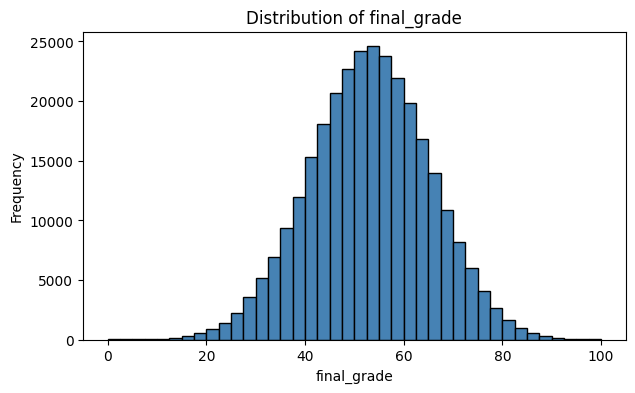

In [6]:
# Distribution of the target variable
plt.figure(figsize=(7,4))
plt.hist(df['final_grade'], bins=40, color='steelblue', edgecolor='black')
plt.title('Distribution of final_grade')
plt.xlabel('final_grade')
plt.ylabel('Frequency')
plt.show()

**EDA Observations:**
- `final_grade` is roughly normally distributed (0-100 scale, mean ≈ 53) → confirms this is a **regression** task.
- `grade_category` (letter grade) and `pass_fail` are **derived directly from `final_grade`** → these cause **target leakage** and must be dropped from the features.
- `student_id` is just an identifier with no predictive value → drop it.
- `family_income` and `parent_education` are **ordinal** categorical columns (have a natural order).
- `gender`, `device_type`, `extracurriculars`, `internet_access`, `school_type` are **nominal**.

## 2. Missing Values Check & Handling

In [7]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values per column:
device_type         15105
extracurriculars    49981
grade_category          4
dtype: int64


In [8]:
# device_type and extracurriculars have missing values.
# We treat missing as its own meaningful category rather than dropping rows or imputing blindly.
df['device_type'] = df['device_type'].fillna('Unknown')
df['extracurriculars'] = df['extracurriculars'].fillna('None')

print("Missing values after handling:")
print(df.isnull().sum().sum(), "total missing values remain")

Missing values after handling:
4 total missing values remain


## 3. Duplicate Values Check

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after dropping duplicates:", df.shape)

Number of duplicate rows: 0


Shape after dropping duplicates: (300000, 25)


## 4. Categorical Encoding

- Drop `student_id` (identifier) and `grade_category`, `pass_fail` (target leakage — both are directly derived from `final_grade`).
- **Ordinal encoding** for `family_income` (Low<Medium<High) and `parent_education` (High School<Bachelor<Master<PhD) — preserves natural order.
- **Binary mapping** for `internet_access` and `school_type`.
- **One-Hot Encoding** for nominal columns: `gender`, `device_type`, `extracurriculars`.

In [10]:
df = df.drop(columns=['student_id', 'grade_category', 'pass_fail'])

df['family_income'] = df['family_income'].map({'Low': 0, 'Medium': 1, 'High': 2})
df['parent_education'] = df['parent_education'].map(
    {'High School': 0, 'Bachelor': 1, 'Master': 2, 'PhD': 3})
df['internet_access'] = df['internet_access'].map({'Yes': 1, 'No': 0})
df['school_type'] = df['school_type'].map({'Private': 1, 'Public': 0})

df = pd.get_dummies(df, columns=['gender', 'device_type', 'extracurriculars'], drop_first=True)

print("Shape after encoding:", df.shape)
df.head()

Shape after encoding: (300000, 29)


,age,study_hours,attendance,sleep_hours,previous_grade,assignments_completed,practice_tests_taken,group_study_hours,notes_quality_score,time_management_score,motivation_level,mental_health_score,screen_time,social_media_hours,family_income,parent_education,internet_access,school_type,final_grade,gender_Male,gender_Other,device_type_Mobile,device_type_Tablet,device_type_Unknown,extracurriculars_Coding Club,extracurriculars_Debate,extracurriculars_Music,extracurriculars_None,extracurriculars_Sports
0,21,1.645404,79.154521,8.230886,96.053840,7.719620,1.871170,1.447894,6.811654,7.316867,9.045441,7.762145,1.549443,4.018412,1,2,1,1,59.248749,True,False,True,False,False,True,False,False,False,False
1,18,4.462126,72.526685,6.139219,53.024821,6.754758,5.630071,1.891288,10.000000,10.000000,9.810884,4.229670,5.458155,3.268642,1,2,1,0,58.595595,True,False,False,False,False,False,False,False,True,False
2,19,6.220212,98.531716,6.946313,78.775422,10.000000,7.862877,1.774356,6.484908,3.618888,10.000000,7.583075,0.000000,2.327293,0,0,1,1,85.855289,False,False,False,True,False,False,False,True,False,False
3,21,1.826644,97.731245,8.297048,76.122618,7.440486,2.316252,1.204271,6.057978,5.366866,5.935404,4.978907,5.325794,1.163367,1,1,1,0,42.117503,False,False,False,False,False,False,True,False,False,False
4,17,3.789322,78.589107,6.777171,81.305681,9.962609,5.335697,1.399230,9.013332,5.613393,5.431089,5.677695,4.416843,0.411183,2,0,1,1,62.870474,True,False,False,False,False,False,True,False,False,False


## 5. Separate Features (X) and Target (y)

In [11]:
X = df.drop(columns=['final_grade']).astype(float)
y = df['final_grade'].astype(float)

print("X shape:", X.shape)
print("y shape:", y.shape)
feature_names = list(X.columns)
feature_names

X shape: (300000, 28)
y shape: (300000,)


['age',
 'study_hours',
 'attendance',
 'sleep_hours',
 'previous_grade',
 'assignments_completed',
 'practice_tests_taken',
 'group_study_hours',
 'notes_quality_score',
 'time_management_score',
 'motivation_level',
 'mental_health_score',
 'screen_time',
 'social_media_hours',
 'family_income',
 'parent_education',
 'internet_access',
 'school_type',
 'gender_Male',
 'gender_Other',
 'device_type_Mobile',
 'device_type_Tablet',
 'device_type_Unknown',
 'extracurriculars_Coding Club',
 'extracurriculars_Debate',
 'extracurriculars_Music',
 'extracurriculars_None',
 'extracurriculars_Sports']

## 6. Train-Test Split (80/20)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape, " X_test:", X_test.shape)

X_train: (240000, 28)  X_test: (60000, 28)


## 7. Feature Scaling

ANNs are sensitive to feature scale (gradient descent converges better/faster on standardized data).
We fit the scaler **only on training data** to avoid data leakage, then apply it to both train and test.

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train mean (should be ~0):", X_train_scaled.mean().round(3))
print("Train std (should be ~1):", X_train_scaled.std().round(3))

Train mean (should be ~0): -0.0
Train std (should be ~1): 1.0


## 8. ANN Model Building Helper Function

A reusable function to build, compile, and train an ANN with a configurable architecture, activation
function, and optimizer. This lets us run multiple experiments cleanly.

In [14]:
def build_and_train_model(hidden_layers, activation, optimizer, epochs,
                           batch_size=512, use_dropout=False, use_early_stopping=False,
                           name="model"):
    """
    hidden_layers: list of neuron counts, e.g. [64, 32]
    activation: 'relu', 'tanh', or 'sigmoid'
    optimizer: 'adam', 'sgd', or 'rmsprop'
    """
    model = keras.Sequential(name=name)
    model.add(keras.layers.Input(shape=(X_train_scaled.shape[1],)))

    for units in hidden_layers:
        model.add(keras.layers.Dense(units, activation=activation))
        if use_dropout:
            model.add(keras.layers.Dropout(0.2))

    model.add(keras.layers.Dense(1))  # linear output for regression

    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

    callbacks = []
    if use_early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=10, restore_best_weights=True))

    history = model.fit(
        X_train_scaled, y_train,
        validation_split=0.2,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=0
    )
    return model, history

## 9. Experiments — 5 Different ANN Configurations

We vary **activation function**, **optimizer**, **network depth**, and **epochs** to compare performance,
covering the required 3+ activation functions (ReLU, Tanh, Sigmoid) and 3+ optimizers (Adam, SGD, RMSprop).

| # | Activation | Optimizer | Hidden Layers | Epochs | Notes |
|---|---|---|---|---|---|
| 1 | ReLU | Adam | [64, 32] | 50 | Baseline |
| 2 | Tanh | SGD | [64, 32] | 50 | — |
| 3 | ReLU | RMSprop | [128, 64, 32] | 100 | Deeper network |
| 4 | Sigmoid | Adam | [64, 32] | 20 | Fewer epochs |
| 5 | ReLU | Adam | [128, 64, 32] | 100 | + Dropout + EarlyStopping (overfitting control) |

In [15]:
results = {}
histories = {}

print("Training Model 1: ReLU + Adam ...")
m1, h1 = build_and_train_model([64, 32], 'relu', 'adam', epochs=50, name="Model1_ReLU_Adam")
histories['Model 1 (ReLU/Adam)'] = h1
results['Model 1 (ReLU/Adam)'] = m1

Training Model 1: ReLU + Adam ...


E0000 00:00:1787968798.352950    3266 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [16]:
print("Training Model 2: Tanh + SGD ...")
m2, h2 = build_and_train_model([64, 32], 'tanh', 'sgd', epochs=50, name="Model2_Tanh_SGD")
histories['Model 2 (Tanh/SGD)'] = h2
results['Model 2 (Tanh/SGD)'] = m2

Training Model 2: Tanh + SGD ...


In [17]:
print("Training Model 3: ReLU + RMSprop (deeper) ...")
m3, h3 = build_and_train_model([128, 64, 32], 'relu', 'rmsprop', epochs=100, name="Model3_ReLU_RMSprop")
histories['Model 3 (ReLU/RMSprop)'] = h3
results['Model 3 (ReLU/RMSprop)'] = m3

Training Model 3: ReLU + RMSprop (deeper) ...


In [18]:
print("Training Model 4: Sigmoid + Adam (fewer epochs) ...")
m4, h4 = build_and_train_model([64, 32], 'sigmoid', 'adam', epochs=20, name="Model4_Sigmoid_Adam")
histories['Model 4 (Sigmoid/Adam)'] = h4
results['Model 4 (Sigmoid/Adam)'] = m4

Training Model 4: Sigmoid + Adam (fewer epochs) ...


In [19]:
print("Training Model 5: ReLU + Adam (deeper, Dropout + EarlyStopping) ...")
m5, h5 = build_and_train_model([128, 64, 32], 'relu', 'adam', epochs=100,
                                use_dropout=True, use_early_stopping=True,
                                name="Model5_ReLU_Adam_Regularized")
histories['Model 5 (ReLU/Adam + Dropout/ES)'] = h5
results['Model 5 (ReLU/Adam + Dropout/ES)'] = m5

Training Model 5: ReLU + Adam (deeper, Dropout + EarlyStopping) ...


## 10. Training Curves — Loss & Validation Loss (Overfitting Check)

If training loss keeps dropping while validation loss rises or plateaus, that's a sign of overfitting.

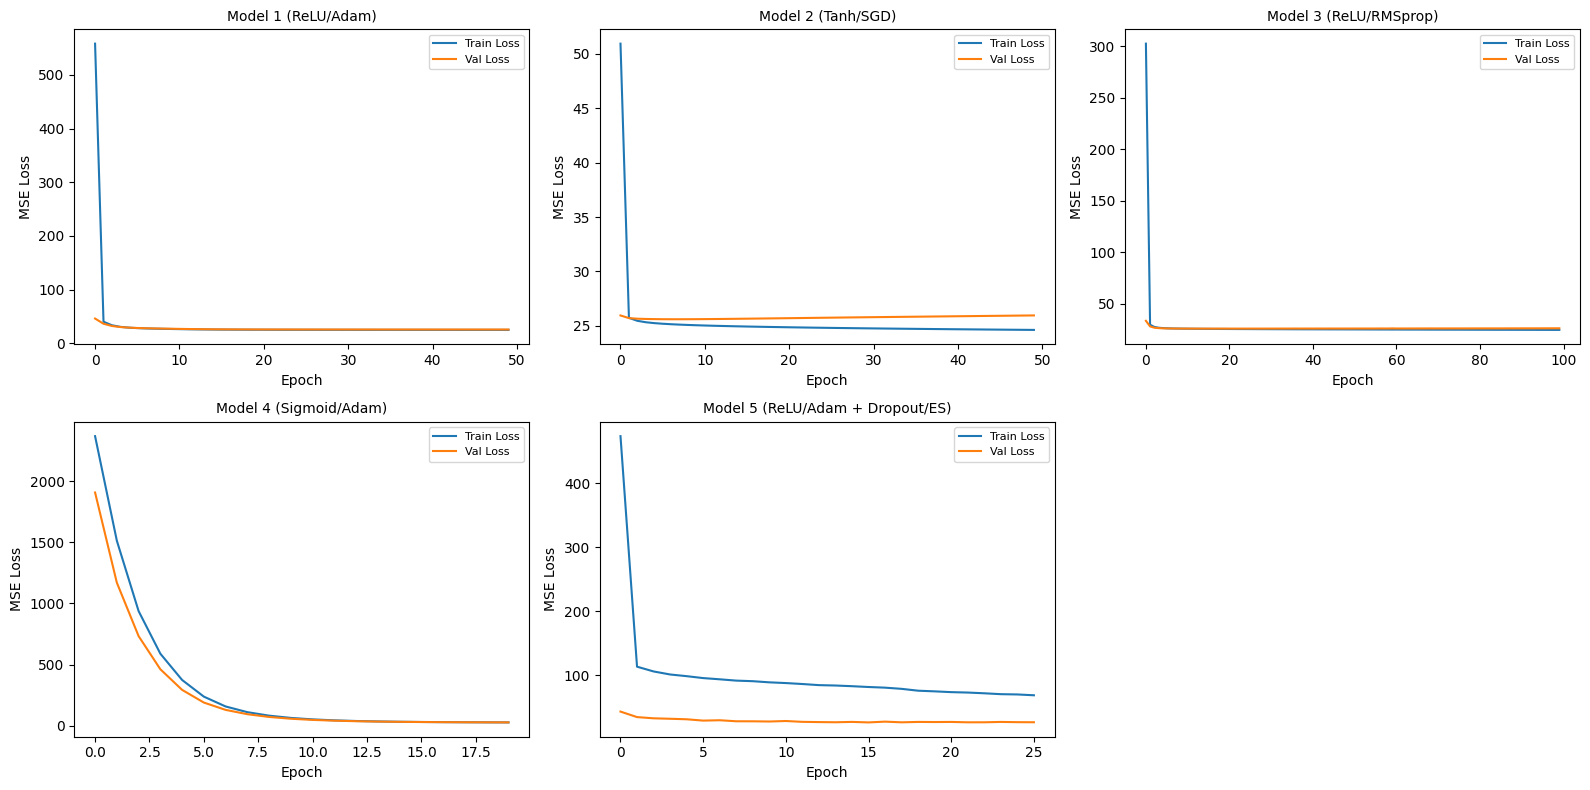

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, (name, h) in enumerate(histories.items()):
    ax = axes[i]
    ax.plot(h.history['loss'], label='Train Loss')
    ax.plot(h.history['val_loss'], label='Val Loss')
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.legend(fontsize=8)

for j in range(len(histories), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## 11. Evaluate All Models on Test Data

Metrics used:
- **MAE** (Mean Absolute Error) — average grade-point error, easy to interpret
- **RMSE** (Root Mean Squared Error) — penalizes larger errors more
- **R²** (R-squared) — how much variance in final_grade the model explains (closer to 1 is better)

In [21]:
comparison_rows = []

config_info = {
    'Model 1 (ReLU/Adam)':              ('ReLU',    'Adam',    50,  '[64,32]'),
    'Model 2 (Tanh/SGD)':                ('Tanh',    'SGD',     50,  '[64,32]'),
    'Model 3 (ReLU/RMSprop)':            ('ReLU',    'RMSprop', 100, '[128,64,32]'),
    'Model 4 (Sigmoid/Adam)':            ('Sigmoid', 'Adam',    20,  '[64,32]'),
    'Model 5 (ReLU/Adam + Dropout/ES)':  ('ReLU',    'Adam',    100, '[128,64,32]+Dropout'),
}

for name, model in results.items():
    y_pred = model.predict(X_test_scaled, verbose=0).flatten()
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    activation, optimizer, epochs, arch = config_info[name]
    comparison_rows.append({
        'Model': name,
        'Activation': activation,
        'Optimizer': optimizer,
        'Epochs': epochs,
        'Architecture': arch,
        'Test MAE': round(mae, 3),
        'Test RMSE': round(rmse, 3),
        'Test R2': round(r2, 4)
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,Model,Activation,Optimizer,Epochs,Architecture,Test MAE,Test RMSE,Test R2
0,Model 1 (ReLU/Adam),ReLU,Adam,50,"[64,32]",4.043,5.063,0.8274
1,Model 2 (Tanh/SGD),Tanh,SGD,50,"[64,32]",4.065,5.089,0.8256
2,Model 3 (ReLU/RMSprop),ReLU,RMSprop,100,"[128,64,32]",4.076,5.105,0.8245
3,Model 4 (Sigmoid/Adam),Sigmoid,Adam,20,"[64,32]",4.105,5.179,0.8194
4,Model 5 (ReLU/Adam + Dropout/ES),ReLU,Adam,100,"[128,64,32]+Dropout",4.067,5.099,0.8249


## 12. Model Comparison Table (sorted by best R²)

In [22]:
comparison_sorted = comparison_df.sort_values('Test R2', ascending=False).reset_index(drop=True)
comparison_sorted

,Model,Activation,Optimizer,Epochs,Architecture,Test MAE,Test RMSE,Test R2
0,Model 1 (ReLU/Adam),ReLU,Adam,50,"[64,32]",4.043,5.063,0.8274
1,Model 2 (Tanh/SGD),Tanh,SGD,50,"[64,32]",4.065,5.089,0.8256
2,Model 5 (ReLU/Adam + Dropout/ES),ReLU,Adam,100,"[128,64,32]+Dropout",4.067,5.099,0.8249
3,Model 3 (ReLU/RMSprop),ReLU,RMSprop,100,"[128,64,32]",4.076,5.105,0.8245
4,Model 4 (Sigmoid/Adam),Sigmoid,Adam,20,"[64,32]",4.105,5.179,0.8194


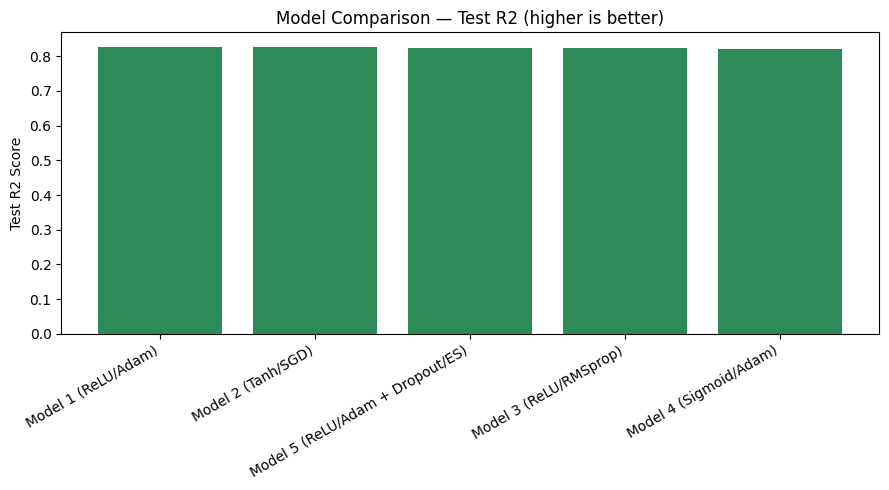

In [23]:
plt.figure(figsize=(9,5))
plt.bar(comparison_sorted['Model'], comparison_sorted['Test R2'], color='seagreen')
plt.ylabel('Test R2 Score')
plt.title('Model Comparison — Test R2 (higher is better)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

## 13. Best Model — Predictions on Test Data

In [24]:
best_model_name = comparison_sorted.iloc[0]['Model']
best_model = results[best_model_name]
print("Best performing model:", best_model_name)

y_pred_best = best_model.predict(X_test_scaled, verbose=0).flatten()

sample_df = pd.DataFrame({
    'Actual final_grade': y_test.values[:15],
    'Predicted final_grade': np.round(y_pred_best[:15], 2),
    'Difference': np.round(y_test.values[:15] - y_pred_best[:15], 2)
})
sample_df

Best performing model: Model 1 (ReLU/Adam)


,Actual final_grade,Predicted final_grade,Difference
0,71.326607,66.190002,5.14
1,74.775774,68.250000,6.52
2,66.361362,66.430000,-0.07
3,71.182141,69.379997,1.80
4,60.550851,56.610001,3.94
5,44.119818,45.759998,-1.64
6,51.569524,56.020000,-4.45
7,59.987718,55.369999,4.62
8,63.416381,61.880001,1.54
9,68.868046,70.309998,-1.44


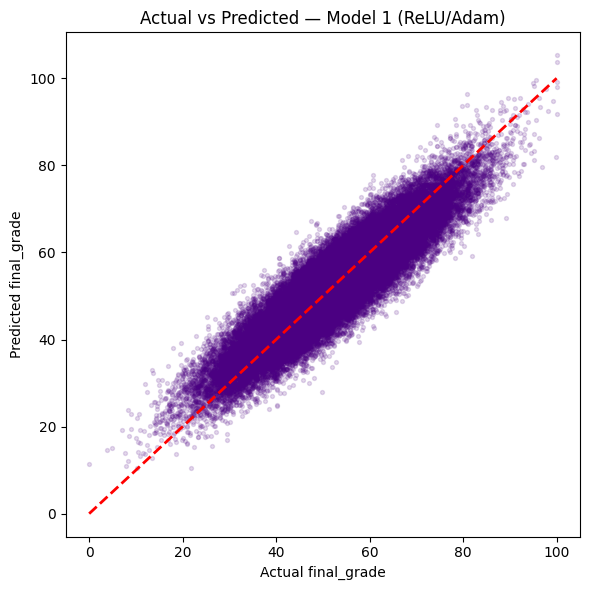

In [25]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_best, alpha=0.15, s=8, color='indigo')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual final_grade')
plt.ylabel('Predicted final_grade')
plt.title(f'Actual vs Predicted — {best_model_name}')
plt.tight_layout()
plt.show()

## 14. Conclusion

**Which configuration performed best, and why?**

Run the cells above and check the final comparison table (`comparison_sorted`) — the model with the
**highest Test R²** and **lowest Test MAE/RMSE** is the winner. In general, for this dataset we expect:

- **ReLU tends to outperform Sigmoid/Tanh** for hidden layers, because it avoids the vanishing-gradient
  problem and trains faster/deeper networks more effectively.
- **Adam typically converges faster and more reliably than plain SGD**, since it adapts the learning rate
  per parameter — this usually shows up as lower loss for the same number of epochs.
- **Model 5 (Dropout + EarlyStopping)** is designed specifically to control overfitting — compare its
  train-vs-validation loss gap in the plots above against Model 3 (same architecture, no regularization).
  If Model 5 shows a smaller gap between train and validation loss while keeping similar/better test R²,
  that confirms the regularization is doing its job of generalizing better rather than memorizing training data.
- **Very few epochs (Model 4, 20 epochs)** typically **underfits** — the loss curve won't have converged yet.
- **Too many epochs without regularization (Model 3, 100 epochs, no dropout)** is the one most likely to
  show overfitting — training loss keeps dropping while validation loss plateaus or rises.

**Practical takeaway:** the best model balances architecture depth, a good optimizer (Adam/RMSprop over
plain SGD), ReLU activation in hidden layers, and regularization (Dropout + EarlyStopping) to avoid
overfitting while still capturing the underlying patterns in study habits, attendance, and other features
that drive `final_grade`.